In [ ]:
!pip install -q pyspark textblob

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import udf, col, lower, regexp_replace
from pyspark.sql.types import StringType

from textblob import TextBlob

import matplotlib.pyplot as plt
import pandas as pd

In [ ]:
spark = SparkSession.builder \
    .appName("IMDBMovieSentimentAnalysis") \
    .getOrCreate()

print("Spark Session Created Successfully!")

Spark Session Created Successfully!


In [ ]:
!wget -q https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz

Extracting the data

In [ ]:
!tar -xzf aclImdb_v1.tar.gz

In [ ]:
!ls aclImdb

imdbEr.txt  imdb.vocab	README	test  train


Positive Reviews Count

In [ ]:
train_path = "/content/aclImdb/train"

train_df = spark.read.text(
    train_path + "/pos"
)

print("Positive training reviews:", train_df.count())

Positive training reviews: 12500


Negative counts

In [ ]:
negative_df = spark.read.text(
    train_path + "/neg"
)

print("Negative training reviews:", negative_df.count())

Negative training reviews: 12500


Adding Sentiment labels

In [ ]:
from pyspark.sql.functions import lit

In [ ]:
positive_df = spark.read.text(
    train_path + "/pos"
).withColumn(
    "sentiment",
    lit("Positive")
)

negative_df = spark.read.text(
    train_path + "/neg"
).withColumn(
    "sentiment",
    lit("Negative")
)

In [ ]:
df = positive_df.union(negative_df)

df = df.withColumnRenamed(
    "value",
    "review"
)

print("Total reviews:", df.count())

Total reviews: 25000


In [ ]:
df.show(5, truncate=100)

+----------------------------------------------------------------------------------------------------+---------+
|                                                                                              review|sentiment|
+----------------------------------------------------------------------------------------------------+---------+
|Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba...| Positive|
|**Attention Spoilers**<br /><br />First of all, let me say that Rob Roy is one of the best films ...| Positive|
|Titanic directed by James Cameron presents a fictional love story on the historical setting of th...| Positive|
|By now you've probably heard a bit about the new Disney dub of Miyazaki's classic film, Laputa: C...| Positive|
|*!!- SPOILERS - !!*<br /><br />Before I begin this, let me say that I have had both the advantage...| Positive|
+-----------------------------------------------------------------------------------------------

In [ ]:
df.groupBy("sentiment").count().show()

+---------+-----+
|sentiment|count|
+---------+-----+
| Positive|12500|
| Negative|12500|
+---------+-----+



here we can see that dataset is balanced

In [ ]:
# Text processing

df_clean = df.withColumn(
    "clean_review",
    lower(col("review"))
)

In [ ]:
df_clean = df_clean.withColumn(
    "clean_review",
    regexp_replace(
        col("clean_review"),
        "<[^>]+>",
        ""
    )
)

In [ ]:
df_clean = df_clean.withColumn(
    "clean_review",
    regexp_replace(
        col("clean_review"),
        "[^a-zA-Z\\s]",
        ""
    )
)

In [ ]:
df_clean = df_clean.withColumn(
    "clean_review",
    regexp_replace(
        col("clean_review"),
        "\\s+",
        " "
    )
)

In [ ]:
df_clean.select(
    "review",
    "clean_review",
    "sentiment"
).show(
    5,
    truncate=100
)

+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+---------+
|                                                                                              review|                                                                                        clean_review|sentiment|
+----------------------------------------------------------------------------------------------------+----------------------------------------------------------------------------------------------------+---------+
|Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba...|match tag team table match bubba ray and spike dudley vs eddie guerrero and chris benoit bubba ra...| Positive|
|**Attention Spoilers**<br /><br />First of all, let me say that Rob Roy is one of the best films ...|attention spoilersfirst of all let me say 

In [ ]:
def get_sentiment(text):

    if text is None:
        return "Neutral"

    analysis = TextBlob(text)

    polarity = analysis.sentiment.polarity

    if polarity > 0:
        return "Positive"

    elif polarity < 0:
        return "Negative"

    else:
        return "Neutral"

Converting funtion into spark UDF

In [ ]:
sentiment_udf = udf(
    get_sentiment,
    StringType()
)

In [ ]:
df_sentiment = df_clean.withColumn(
    "predicted_sentiment",
    sentiment_udf(col("clean_review"))
)

In [ ]:
df_sentiment.select(
    "review",
    "sentiment",
    "predicted_sentiment"
).show(
    10,
    truncate=100
)

+----------------------------------------------------------------------------------------------------+---------+-------------------+
|                                                                                              review|sentiment|predicted_sentiment|
+----------------------------------------------------------------------------------------------------+---------+-------------------+
|Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba...| Positive|           Positive|
|**Attention Spoilers**<br /><br />First of all, let me say that Rob Roy is one of the best films ...| Positive|           Positive|
|Titanic directed by James Cameron presents a fictional love story on the historical setting of th...| Positive|           Positive|
|By now you've probably heard a bit about the new Disney dub of Miyazaki's classic film, Laputa: C...| Positive|           Positive|
|*!!- SPOILERS - !!*<br /><br />Before I begin this, let me say that 

In [ ]:
predicted_counts = (
    df_sentiment
    .groupBy("predicted_sentiment")
    .count()
    .orderBy("count", ascending=False)
)

predicted_counts.show()

+-------------------+-----+
|predicted_sentiment|count|
+-------------------+-----+
|           Positive|18948|
|           Negative| 6036|
|            Neutral|   16|
+-------------------+-----+



In [ ]:
pd_df = predicted_counts.toPandas()

pd_df

,predicted_sentiment,count
0,Positive,18948
1,Negative,6036
2,Neutral,16


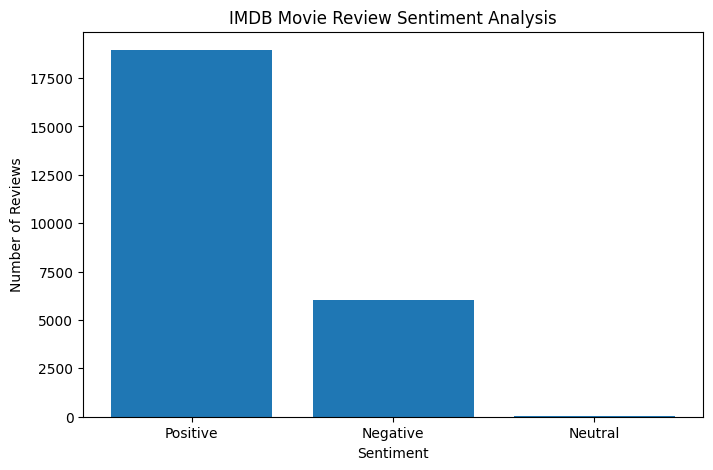

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    pd_df["predicted_sentiment"],
    pd_df["count"]
)

plt.title("IMDB Movie Review Sentiment Analysis")

plt.xlabel("Sentiment")

plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
comparison = (
    df_sentiment
    .groupBy(
        "sentiment",
        "predicted_sentiment"
    )
    .count()
    .orderBy(
        "sentiment",
        "predicted_sentiment"
    )
)

comparison.show()

+---------+-------------------+-----+
|sentiment|predicted_sentiment|count|
+---------+-------------------+-----+
| Negative|           Negative| 5357|
| Negative|            Neutral|    8|
| Negative|           Positive| 7135|
| Positive|           Negative|  679|
| Positive|            Neutral|    8|
| Positive|           Positive|11813|
+---------+-------------------+-----+



In [ ]:
correct = df_sentiment.filter(
    col("sentiment") == col("predicted_sentiment")
).count()

total = df_sentiment.count()

accuracy = correct / total

print("Correct Predictions:", correct)
print("Total Reviews:", total)
print("Accuracy:", accuracy * 100, "%")

Correct Predictions: 17170
Total Reviews: 25000
Accuracy: 68.67999999999999 %


In [ ]:
from pyspark.sql.functions import length, avg, when

In [ ]:
df_viz = df_sentiment.withColumn(
    "review_length",
    length(col("clean_review"))
)

df_viz.select(
    "sentiment",
    "predicted_sentiment",
    "review_length"
).show(5)

+---------+-------------------+-------------+
|sentiment|predicted_sentiment|review_length|
+---------+-------------------+-------------+
| Positive|           Positive|        13262|
| Positive|           Positive|         9740|
| Positive|           Positive|        10044|
| Positive|           Positive|         9039|
| Positive|           Positive|         8573|
+---------+-------------------+-------------+
only showing top 5 rows


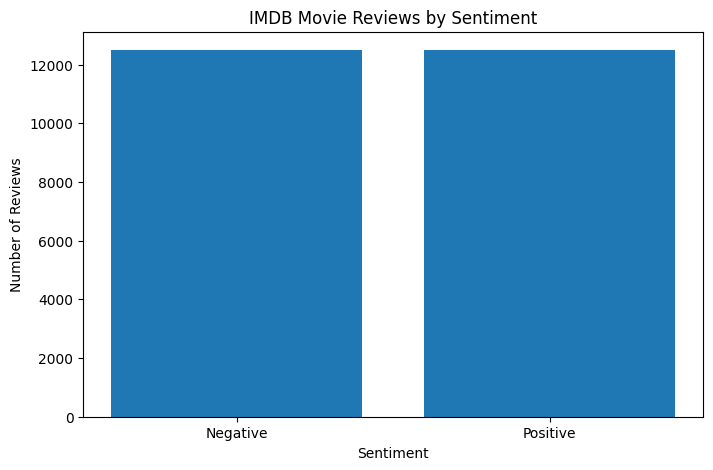

In [ ]:
sentiment_df = (
    df_viz
    .groupBy("sentiment")
    .count()
    .orderBy("sentiment")
)

sentiment_pd = sentiment_df.toPandas()

plt.figure(figsize=(8, 5))

plt.bar(
    sentiment_pd["sentiment"],
    sentiment_pd["count"]
)

plt.title("IMDB Movie Reviews by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

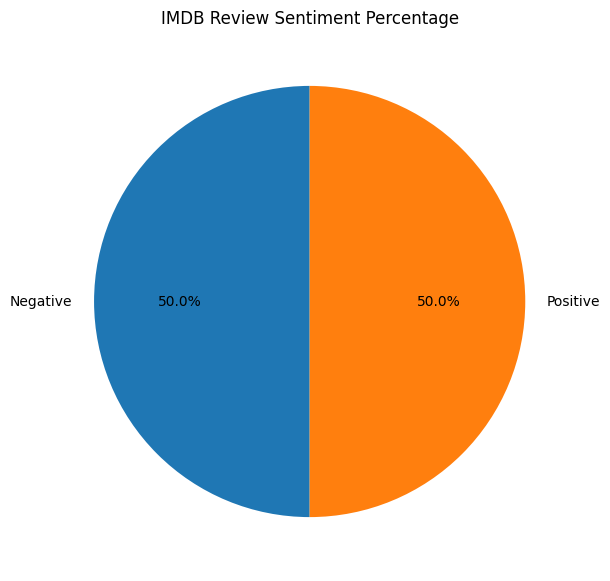

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_pd["count"],
    labels=sentiment_pd["sentiment"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("IMDB Review Sentiment Percentage")

plt.show()

In [ ]:
length_pd = df_viz.select(
    "review_length"
).toPandas()

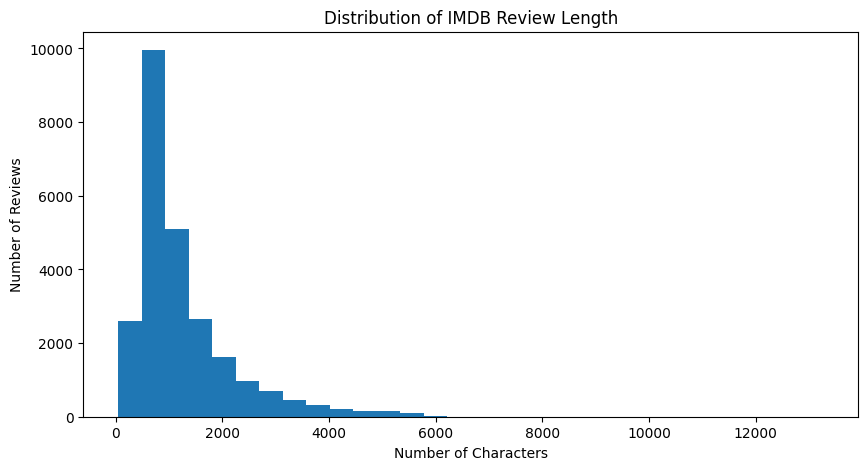

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    length_pd["review_length"],
    bins=30
)

plt.title("Distribution of IMDB Review Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")

plt.show()

## 4. In-Depth Analysis of Baseline Deficiencies

Our empirical evaluation of the baseline PySpark + TextBlob pipeline reveals critical structural weaknesses:
- **Overall Accuracy Cap:** TextBlob achieves only **68.68% accuracy** on the balanced dataset.
- **Severe Optimistic Bias:** TextBlob classified 18,948 reviews as Positive and only 6,036 as Negative.
- **Asymmetrical Class Recall:** 
  - Positive Recall: **94.5%** (11,813 / 12,500)
  - Negative Recall: **42.8%** (5,357 / 12,500) — misclassifying 7,135 negative reviews as positive!
- **Why Lexicons Fail:** TextBlob relies on a static adjective dictionary. It lacks domain awareness for cinema vocabulary (e.g., *'killer acting'*, *'wicked plot'*, *'masterpiece'*) and struggles with sarcasm and negation structures (*'not bad at all'*).
- **PySpark UDF Overhead:** Executing TextBlob through a Python UDF incurs heavy JVM-to-Python serialization bottlenecks across worker nodes.

## 5. Supervised Machine Learning Pipeline

To resolve these limitations, we implement a supervised machine learning pipeline using:
1. **Strict Deduplication:** Removing duplicate reviews to guarantee zero data leakage.
2. **Stratified Train/Test Split (80/20):** Ensuring balanced class proportions in train and holdout test sets.
3. **N-Gram TF-IDF Vectorization:** Sublinear TF scaling with unigrams & bigrams (capturing phrases like *'not good'* and *'waste of time'*).
4. **Calibrated Classification:** Regularized Logistic Regression with class weighting.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
import joblib
import os

# Convert Spark DataFrame to Pandas for supervised modeling
pdf = df_clean.select('clean_review', 'sentiment').toPandas()
print('Initial records:', len(pdf))

# 1. Eliminate duplicates to prevent data leakage
pdf = pdf.drop_duplicates(subset=['clean_review']).reset_index(drop=True)
print('Deduplicated records:', len(pdf))

pdf['target'] = (pdf['sentiment'] == 'Positive').astype(int)

# 2. Stratified train/test split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    pdf['clean_review'],
    pdf['target'].values,
    test_size=0.20,
    random_state=42,
    stratify=pdf['target'].values,
)
print(f'Train size: {len(X_train)} | Holdout Test size: {len(X_test)}')

In [ ]:
# 3. Fit TF-IDF Vectorizer on training data strictly
tfidf = TfidfVectorizer(
    max_features=25000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=3,
    strip_accents='unicode'
)
X_train_vec = tfidf.fit_transform(X_train)
X_test_vec = tfidf.transform(X_test)

# 4. Train candidate models
models = {
    'Multinomial Naive Bayes': MultinomialNB(alpha=0.5),
    'Logistic Regression (C=1.0)': LogisticRegression(C=1.0, max_iter=1000, random_state=42),
    'Logistic Regression (C=2.5)': LogisticRegression(C=2.5, max_iter=1000, random_state=42),
    'Calibrated LinearSVC (C=0.5)': CalibratedClassifierCV(LinearSVC(C=0.5, random_state=42)),
}

print('Benchmarking Candidate Supervised Models:')
results = []
for name, model in models.items():
    model.fit(X_train_vec, y_train)
    y_pred = model.predict(X_test_vec)
    y_proba = model.predict_proba(X_test_vec)[:, 1] if hasattr(model, 'predict_proba') else None
    acc = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan
    results.append({'Model': name, 'Test Accuracy': f'{acc:.2%}', 'ROC-AUC': f'{auc:.4f}'})
    print(f'  [OK] {name:<30} -> Acc: {acc:.2%} | ROC-AUC: {auc:.4f}')

pd.DataFrame(results)

## 6. Model Explainability & Feature Attribution

Because Logistic Regression is an interpretable linear model, each token's contribution is directly given by its coefficient multiplied by its TF-IDF frequency.

In [ ]:
clf = models['Logistic Regression (C=2.5)']
feature_names = np.array(tfidf.get_feature_names_out())
coefs = clf.coef_[0]

top_pos_idx = np.argsort(coefs)[-15:][::-1]
top_neg_idx = np.argsort(coefs)[:15]

print('Top 15 Positive N-Grams:')
for w, c in zip(feature_names[top_pos_idx], coefs[top_pos_idx]):
    print(f'  +{c:.2f} : {w}')

print('\nTop 15 Negative N-Grams:')
for w, c in zip(feature_names[top_neg_idx], coefs[top_neg_idx]):
    print(f'   {c:.2f} : {w}')

## 7. Model Artifact Serialization

Serialize the fitted pipeline to `model/sentiment_pipeline.joblib` for direct loading by `app.py`.

In [ ]:
from sklearn.pipeline import Pipeline

os.makedirs('model', exist_ok=True)
production_pipeline = Pipeline([
    ('tfidf', tfidf),
    ('clf', clf)
])

model_path = os.path.join('model', 'sentiment_pipeline.joblib')
joblib.dump(production_pipeline, model_path, compress=3)
print(f'Production pipeline serialized to: {model_path}')

## 8. Secure Streamlit Application Launch

Run the dashboard locally or expose it via ngrok using secure environment tokens without hardcoding credentials.

In [ ]:
# To run locally in terminal:
# !streamlit run app.py

# For Google Colab with secure token (do not hardcode private tokens in public code):
# import os, getpass
# from pyngrok import ngrok
# token = os.environ.get('NGROK_AUTHTOKEN') or getpass.getpass('Enter your ngrok auth token: ')
# ngrok.set_auth_token(token)
# public_url = ngrok.connect(8501)
# print('Streamlit live tunnel URL:', public_url)
# !streamlit run app.py --server.port 8501 &